# **Track A -- Time Series Forecasting**

## **Part 1 — Define the problem and establish a baseline**
### **Task 01 — Load, inspect, and define the prediction task**

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("prophet").setLevel(logging.ERROR)
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

In [2]:
# load the dataset
df = pd.read_csv("retail_sales.csv")

print("Shape:", df.shape)
print("Columns:", df.columns.to_list())

Shape: (1461, 5)
Columns: ['date', 'sales', 'store_id', 'promo', 'temp_c']


In [3]:
print("Data Type:", df.dtypes)

Data Type: date            str
sales       float64
store_id        str
promo         int64
temp_c      float64
dtype: object


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
date        0
sales       6
store_id    0
promo       0
temp_c      0
dtype: int64

Duplicate Rows: 0


In [5]:
df.head()

,date,sales,store_id,promo,temp_c
0,2021-01-01,1298.13,ST001,1,8.2
1,2021-01-02,2257.93,ST001,0,5.3
2,2021-01-03,2116.99,ST001,1,7.8
3,2021-01-04,1677.36,ST001,0,0.1
4,2021-01-05,1818.43,ST001,0,11.6


In [6]:
df.describe(include="all")

,date,sales,store_id,promo,temp_c
count,1461,1455.000000,1461,1461.000000,1461.000000
unique,1461,NaN,1,NaN,NaN
top,2021-01-01,NaN,ST001,NaN,NaN
freq,1,NaN,1461,NaN,NaN
mean,NaN,3328.265546,NaN,0.153320,17.964819
std,NaN,645.576807,NaN,0.360419,9.003178
min,NaN,1298.130000,NaN,0.000000,-1.600000
25%,NaN,2882.565000,NaN,0.000000,9.700000
50%,NaN,3318.700000,NaN,0.000000,18.000000
75%,NaN,3780.700000,NaN,0.000000,26.000000


In [7]:
# Prepare the daily time series
df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date")
df = df.drop_duplicates(subset="date")
df = df.set_index("date").asfreq("D")

print("Start Date", df.index.min())
print("End Date", df.index.max())
print("Missing Values:\n",df.isnull().sum())

Start Date 2021-01-01 00:00:00
End Date 2024-12-31 00:00:00
Missing Values:
 sales       6
store_id    0
promo       0
temp_c      0
dtype: int64


In [8]:
print("Missing sales before filling -", df["sales"].isnull().sum())

Missing sales before filling - 6


In [9]:
df["sales"] = df["sales"].interpolate(method="linear")
df["sales"] = df["sales"].ffill().bfill()

print("Missing sales after filling -", df["sales"].isnull().sum())

Missing sales after filling - 0


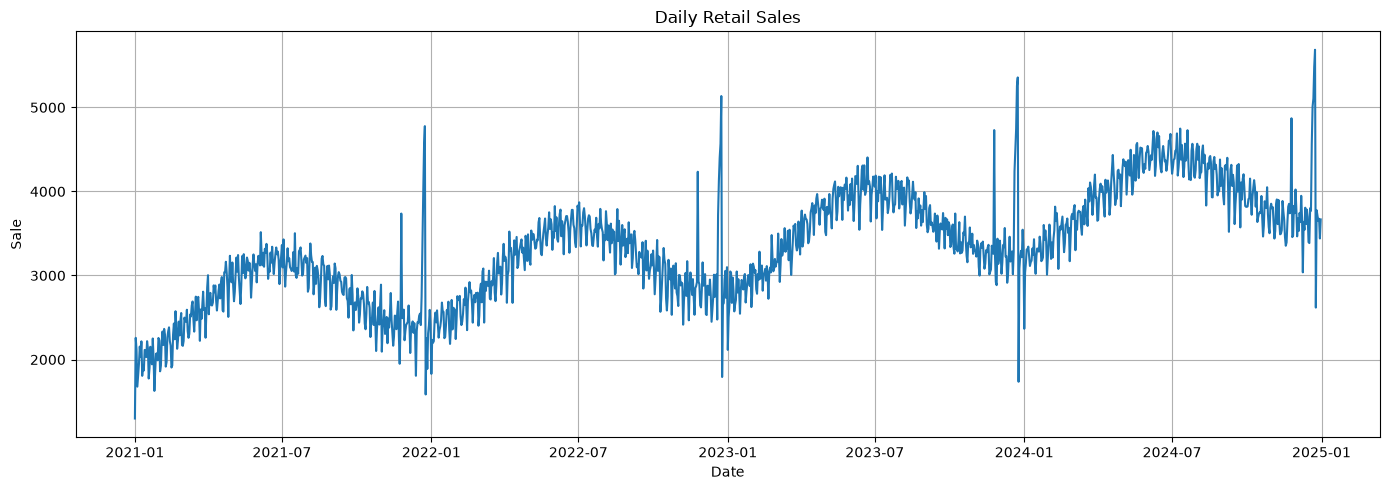

In [10]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df.index, df["sales"])
ax.set_title("Daily Retail Sales")
ax.set_xlabel("Date")
ax.set_ylabel("Sale")
ax.grid(True)

plt.tight_layout()
plt.show()

**Prediction Task -->**
* The goal is to forecast daily retail sales using historical sales observations and information available at forecast time. The forecast horizon is one day ahead, with forecasts refreshed daily. The latest 56 days are reserved for final testing, while earlier observations are used for training and validation.
* The main evaluation metric is Mean Absolute Error (MAE). A seasonal-naive model using sales from seven days earlier will serve as the baseline. Stronger machine learning models will be compared using time-based validation. The final test period will remain untouched during model selection.
* Potential limitations include changing customer demand, missing observations, promotions, holidays, and the absence of external variables that may affect sales.

### **Task 02 — Make a leakage-safe evaluation split**

In [11]:
# Split the data
test_size = 56

train_val = df.iloc[:-test_size].copy()
test = df.iloc[-test_size:].copy()

print("Training + Validation Shape:", train_val.shape)
print("Training + Validation Period:", train_val.index.min(), "to", train_val.index.max())
print("Test Period:", test.index.min(), "to", test.index.max())

Training + Validation Shape: (1405, 4)
Training + Validation Period: 2021-01-01 00:00:00 to 2024-11-05 00:00:00
Test Period: 2024-11-06 00:00:00 to 2024-12-31 00:00:00


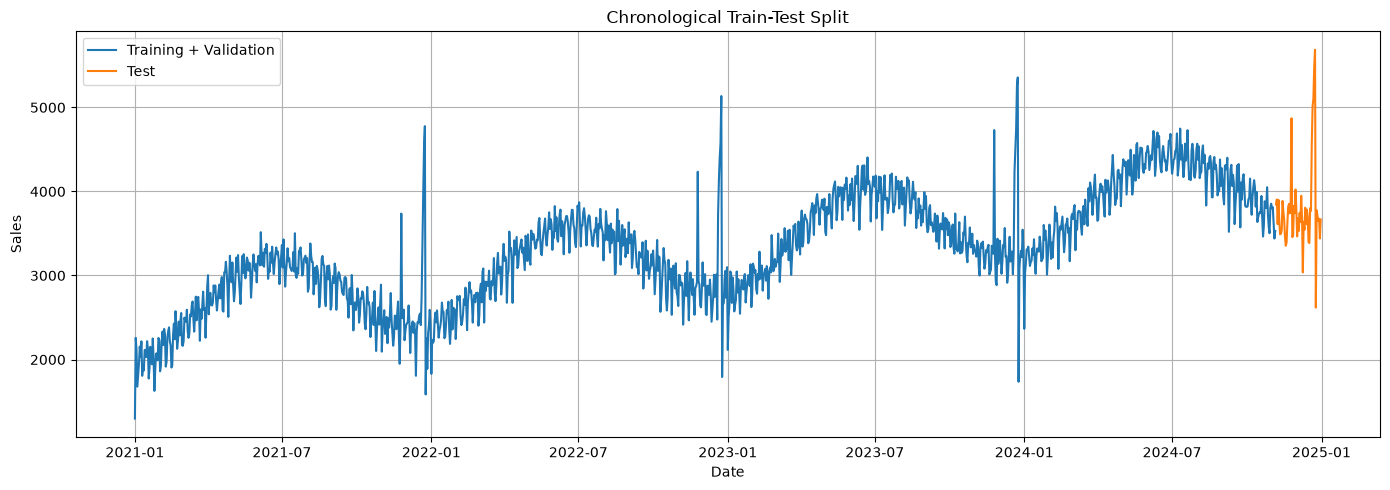

In [12]:
# Visualize the split
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(train_val.index, train_val["sales"], label="Training + Validation")
ax.plot(test.index, test["sales"], label="Test")

ax.set_title("Chronological Train-Test Split")
ax.set_xlabel("Date")
ax.set_ylabel("Sales")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

**Evaluation Split -->**
* The dataset is sorted chronologically. The final 56 daily observations are reserved as the untouched test set, and all earlier observations are used for model development and validation.
* Random shuffling is avoided because it could allow information from later dates to influence predictions for earlier dates. Expanding-window time-series cross-validation will be used to compare models.
* The forecast is one day ahead and refreshed daily. Therefore, previously observed sales may be used as lag features. This is a warm-start forecasting setup, not a cold-start problem. The evaluation does not guarantee performance during unusual future events or major changes in demand.

### **Task 03 — Build a simple baseline first**

In [13]:
baseline_start = time.time()
baseline_predictions = test["sales"].shift(7)
baseline_predictions = df["sales"].shift(7).loc[test.index]

baseline_mae = mean_absolute_error(test["sales"], baseline_predictions)

baseline_rmse = np.sqrt(mean_squared_error(test["sales"], baseline_predictions))

baseline_time = time.time() - baseline_start

print("Seasonal Naive Test MAE:", round(baseline_mae, 2))
print("Seasonal Naive Test RMSE:", round(baseline_rmse, 2))
print("Runtime:", round(baseline_time, 4), "Seconds")

Seasonal Naive Test MAE: 446.42
Seasonal Naive Test RMSE: 775.99
Runtime: 0.0129 Seconds


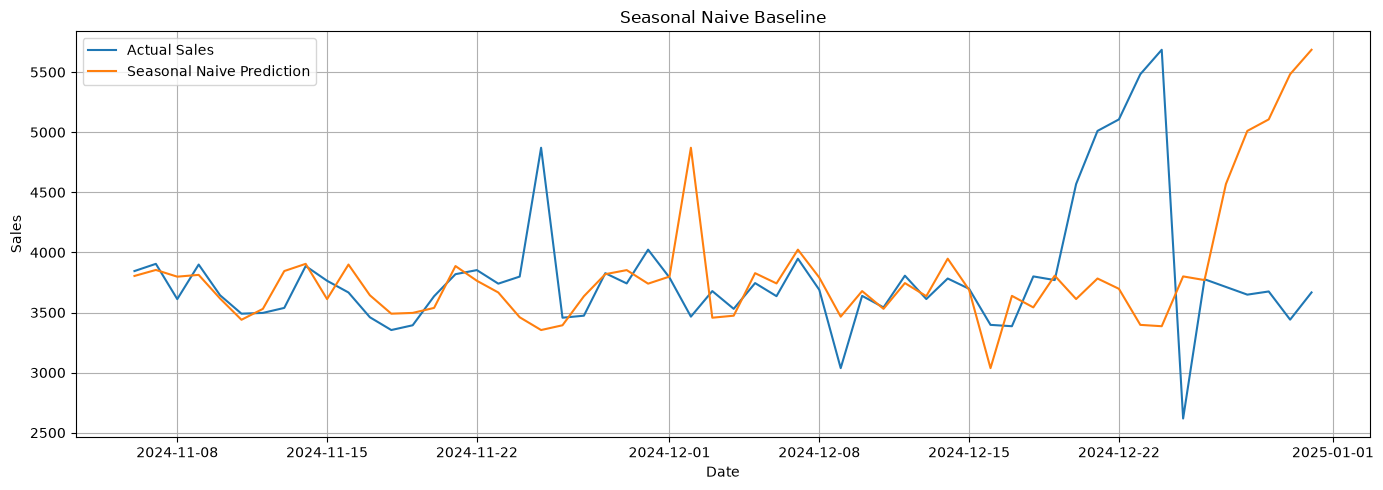

In [14]:
# Plot actual vs predict sales
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(test.index, test["sales"], label="Actual Sales")
ax.plot(test.index, baseline_predictions, label="Seasonal Naive Prediction")

ax.set_title("Seasonal Naive Baseline")
ax.set_xlabel("Date")
ax.set_ylabel("Sales")
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

**Baseline Conclusion -->**
* The seasonal-naive baseline predicts sales using the observation from seven days earlier. This is a meaningful starting point when retail demand has a weekly pattern.
* MAE measures the average absolute prediction error in the original sales units, while RMSE penalizes larger errors more strongly. These metrics do not explain the cause of prediction errors and may hide differences across weekdays or seasonal periods.
* The baseline scores will be compared with stronger models using the same evaluation protocol.

### **Task 04 — Inspect patterns and define candidate features**

In [15]:
data = df[["sales"]].copy()

data["day_of_week"] = data.index.dayofweek
data["day_of_month"] = data.index.day
data["month"] = data.index.month
data["quarter"] = data.index.quarter
data["week_of_year"] = data.index.isocalendar().week.astype(int)

data["lag_1"] = data["sales"].shift(1)
data["lag_7"] = data["sales"].shift(7)
data["lag_14"] = data["sales"].shift(14)
data["lag_28"] = data["sales"].shift(28)

data["rolling_mean_7"] = data["sales"].shift(1).rolling(7).mean()
data["rolling_mean_28"] = data["sales"].shift(1).rolling(28).mean()
data["rolling_std_7"] = data["sales"].shift(1).rolling(7).std()

data = data.dropna()

display(round(data.head(), 3))

,sales,day_of_week,day_of_month,month,quarter,week_of_year,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28,rolling_std_7
date,,,,,,,,,,,,,
2021-01-29,1990.79,4,29,1,1,4,2073.50,1943.30,2029.44,1298.13,1977.226,1980.961,195.354
2021-01-30,2256.80,5,30,1,1,4,1990.79,2250.28,2218.10,2257.93,1984.010,2005.699,194.803
2021-01-31,2229.18,6,31,1,1,4,2256.80,2009.92,2133.79,2116.99,1984.941,2005.658,196.298
2021-02-01,1859.82,0,1,2,1,5,2229.18,1626.60,1774.04,1677.36,2016.264,2009.665,217.316
2021-02-02,1925.10,1,2,2,1,5,1859.82,1868.89,1899.21,1818.43,2049.581,2016.181,157.176


In [16]:
print("Feature Dataset Shape:", data.shape)

Feature Dataset Shape: (1433, 13)


In [17]:
# Saperate features and target
X = data.drop(columns=["sales"])
y = data["sales"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)
print("\nFeatures:", X.columns.tolist())

X Shape: (1433, 12)
y Shape: (1433,)

Features: ['day_of_week', 'day_of_month', 'month', 'quarter', 'week_of_year', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'rolling_std_7']


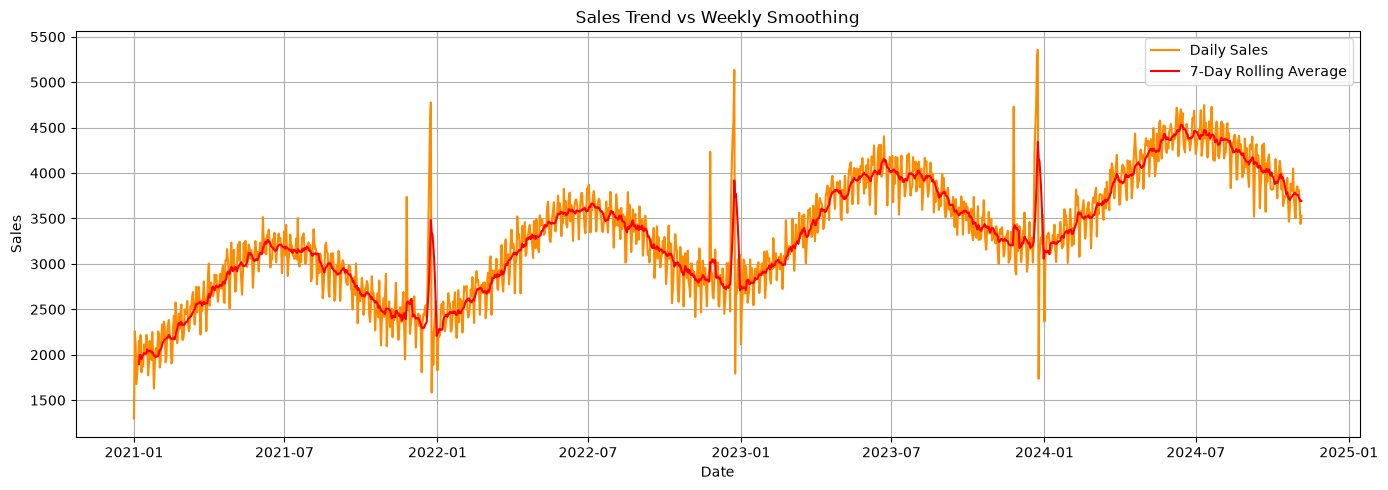

In [18]:
# Plot training sales and a rolling average
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(train_val.index, train_val["sales"], label="Daily Sales", color="darkorange")
rolling_avg = train_val["sales"].rolling(7).mean()
ax.plot(train_val.index, rolling_avg, label="7-Day Rolling Average", color="red")

ax.set_title("Sales Trend vs Weekly Smoothing")
ax.set_xlabel("Date")
ax.set_ylabel("Sales")
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

**Feature Engineering -->**
* Lag features represent previously observed sales from one, seven, fourteen, and twenty-eight days earlier. Rolling means summarize recent demand, while the rolling standard deviation measures recent variability.
* Calendar features represent the weekday, day of the month, month, quarter, and week of the year. They are known in advance and can be calculated at forecast time.
* All rolling features are shifted by one day before calculation to prevent the current target from entering its own predictors. Feature definitions are based on historical sales, and the final test labels are not used for feature selection.

## **Part 2 — Compare models, evaluate honestly, and plan production**
### **Task 05 — Train and compare at least two stronger approaches**

In [19]:
# Set up development data
from sklearn.model_selection import TimeSeriesSplit

X_dev = X.loc[X.index <= train_val.index.max()].copy()
y_dev = y.loc[X_dev.index].copy()

X_test = X.loc[X.index.isin(test.index)].copy()
y_test = y.loc[X_test.index].copy()

print("Development X Shape:", X_dev.shape)
print("Development y Shape:", y_dev.shape)
print("Test X Shape:", X_test.shape)
print("Test y Shape:", y_test.shape)

Development X Shape: (1377, 12)
Development y Shape: (1377,)
Test X Shape: (56, 12)
Test y Shape: (56,)


In [20]:
# Create time based validation folds
tscv = TimeSeriesSplit(n_splits=3)

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_dev), start=1):
    print(f"Fold {fold}")
    print("Train Period:", X_dev.index[train_idx[0]], "to", 
         X_dev.index[train_idx[-1]])
    print("Validation Period:", X_dev.index[val_idx[0]], "to", 
         X_dev.index[val_idx[-1]])
    print()

Fold 1
Train Period: 2021-01-29 00:00:00 to 2022-01-08 00:00:00
Validation Period: 2022-01-09 00:00:00 to 2022-12-18 00:00:00

Fold 2
Train Period: 2021-01-29 00:00:00 to 2022-12-18 00:00:00
Validation Period: 2022-12-19 00:00:00 to 2023-11-27 00:00:00

Fold 3
Train Period: 2021-01-29 00:00:00 to 2023-11-27 00:00:00
Validation Period: 2023-11-28 00:00:00 to 2024-11-05 00:00:00



In [21]:
# Define the model configurations
models = {
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=2,
                                          random_state=42),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                                      l2_regularization=1.0, random_state=42)
}

In [22]:
# Compare models using validation MAE:
cv_results = []

for model_name, model in models.items():
    fold_mae = []
    fold_rmse = []
    start_time = time.time()

    for train_idx, val_idx in tscv.split(X_dev):
        X_train_fold = X_dev.iloc[train_idx]
        y_train_fold = y_dev.iloc[train_idx]

        X_val_fold = X_dev.iloc[val_idx]
        y_val_fold = y_dev.iloc[val_idx]

        model.fit(X_train_fold, y_train_fold)
        predictions = model.predict(X_val_fold)

        fold_mae.append(mean_absolute_error(y_val_fold, predictions))
        fold_rmse.append(np.sqrt(mean_squared_error(y_val_fold, predictions)))

    runtime = time.time() - start_time

    cv_results.append({
        "Model": model_name,
        "Mean Validation MAE": np.mean(fold_mae),
        "Mean Validation RMSE": np.mean(fold_rmse),
        "MAE Std.": np.std(fold_mae),
        "Runtime Seconds": runtime
    })



cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(3))

,Model,Mean Validation MAE,Mean Validation RMSE,MAE Std.,Runtime Seconds
0,Random Forest,184.679,259.316,12.112,1.140
1,Gradient Boosting,192.724,267.877,7.373,0.302


**Model Comparison -->**
* Random Forest combines predictions from multiple decision trees and can capture nonlinear relationships. Histogram-based Gradient Boosting builds trees sequentially, with each stage improving the previous model's predictions.
* Both approaches are evaluated using expanding-window time-series cross-validation. The model with lower mean validation MAE is preferred, provided its performance is reasonably consistent across folds.
* Training runtime and variation between validation folds are also considered. The final test set is not used to choose the model.

### **Task 06 — Tune without touching the test set**

In [23]:
# Define candidate configurations
candidates = {
    "RF_100": RandomForestRegressor(n_estimators=100, max_depth=8, min_samples_leaf=2,
                                   random_state=42),
    "RF_200": RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=2,
                                   random_state=42),
    "HGB_100": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.05, max_leaf_nodes=15,
                                            l2_regularization=1.0, random_state=42),
    "HGB_200": HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                            l2_regularization=1.0, random_state=42)
}

In [24]:
# Evaluate every candidate
tuning_results = []

for model_name, model in candidates.items():
    scores = []
    start_time = time.time()

    for train_idx, val_idx in tscv.split(X_dev):
        X_train_fold = X_dev.iloc[train_idx]
        y_train_fold = y_dev.iloc[train_idx]

        X_val_fold = X_dev.iloc[val_idx]
        y_val_fold = y_dev.iloc[val_idx]

        model.fit(X_train_fold, y_train_fold)
        predictions = model.predict(X_val_fold)

        scores.append(mean_absolute_error(y_val_fold, predictions))

    tuning_results.append({
        "Configuration": model_name,
        "Mean Validation MAE": np.mean(scores),
        "Validation MAE Std": np.std(scores),
        "Runtime Seconds": time.time() - start_time
    })


tuning_df = pd.DataFrame(tuning_results)
tuning_df = tuning_df.sort_values("Mean Validation MAE")

display(tuning_df.round(3))

,Configuration,Mean Validation MAE,Validation MAE Std,Runtime Seconds
1,RF_200,185.088,11.739,1.152
0,RF_100,185.511,15.803,0.522
3,HGB_200,192.724,7.373,0.303
2,HGB_100,192.880,8.415,0.182


In [25]:
# Select the best configuration
best_name = tuning_df.iloc[0]["Configuration"]
best_model = candidates[best_name]

print("Best Configuration:", best_name)
print("Best Mean Validation MAE:", 
     round(tuning_df.iloc[0]["Mean Validation MAE"], 3))

Best Configuration: RF_200
Best Mean Validation MAE: 185.088


**Hyperparameter Tuning -->**
* A small set of Random Forest and Gradient Boosting configurations is compared using the same expanding-window validation folds. The configuration with the lowest mean validation MAE is selected.
* The validation standard deviation helps identify configurations whose performance varies substantially between periods. Only training and validation observations are used for model selection. The final test period remains reserved for the final evaluation.
* A configuration selected by validation is not guaranteed to be the best model for every future period.

### **Task 07 — Evaluate the final model once and analyze errors**

In [26]:
# Fit the selected model
final_model = candidates[best_name]
final_model.fit(X_dev, y_dev)
final_predictions = final_model.predict(X_test)

print("Final Model:", best_name)

Final Model: RF_200


In [27]:
# Evaluate the baseline and final model
# Seasonal naive: sales from seven days earlier
baseline_test_preditions = df["sales"].shift(7).loc[X_test.index]
baseline_test_mae = mean_absolute_error(y_test, baseline_test_preditions)
baseline_test_rmse = np.sqrt(mean_squared_error(y_test, baseline_test_preditions))

final_test_mae = mean_absolute_error(y_test, final_predictions)
final_test_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))

comparison = pd.DataFrame({
    "Model": ["Seasonal Naive", best_name],
    "MAE": [baseline_test_mae, final_test_mae],
    "RMSE": [baseline_test_rmse, final_test_rmse]
})

display(comparison.round(3))

,Model,MAE,RMSE
0,Seasonal Naive,446.425,775.987
1,RF_200,275.649,443.234


In [28]:
# Calculate improvement over baseline
mae_improvement = baseline_test_mae - final_test_mae
improvement_percent = ((baseline_test_mae - final_test_mae) / baseline_test_mae * 100
                      if baseline_test_mae != 0 else np.nan)

print("Baseline MAE:", round(baseline_test_mae, 3))
print("Final model MAE:", round(final_test_mae, 3))
print("MAE Improvement:", round(mae_improvement, 3))
print("Improvement (%):", round(improvement_percent, 2))

Baseline MAE: 446.425
Final model MAE: 275.649
MAE Improvement: 170.776
Improvement (%): 38.25


* A positive improvement means the final model has lower MAE than the baseline.
* A negative result means the baseline performed better.

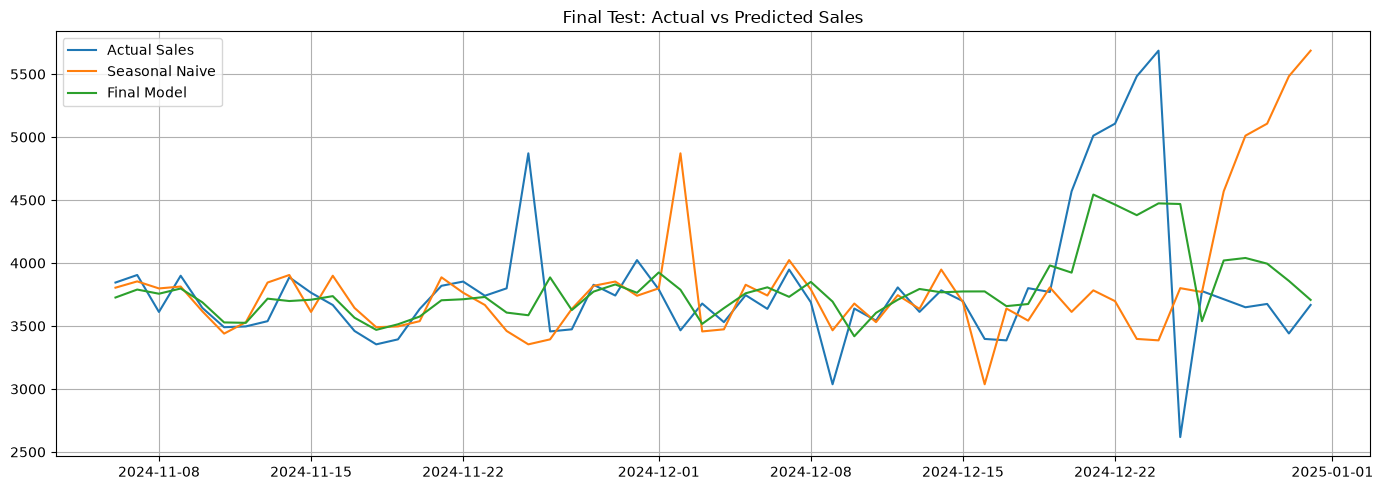

In [36]:
# Predict actual vs predicted sales
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(y_test.index, y_test, label="Actual Sales")
ax.plot(y_test.index, baseline_test_preditions, label="Seasonal Naive")
ax.plot(y_test.index, final_predictions, label="Final Model")

ax.set_title("Final Test: Actual vs Predicted Sales")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.savefig("final_forecast_comparison.png", dpi=150)
plt.show()

In [34]:
# Analyze errors by weekdays 
error_analysis = pd.DataFrame({
    "Actual": y_test,
    "Predicted": final_predictions
}, index=y_test.index)

error_analysis["Absolute Error"] = (error_analysis["Actual"] - error_analysis["Predicted"]).abs()
error_analysis["Weekday"] = error_analysis.index.day_name()

weekly_errors = (error_analysis.groupby("Weekday")["Absolute Error"]
                .agg(["mean", "count"])
                .rename(columns={
                    "mean": "Mean Absolute Error",
                    "count": "Number of Observations"
                }))

display(weekly_errors.round(3))

,Mean Absolute Error,Number of Observations
Weekday,,
Friday,216.776,8
Monday,539.323,8
Saturday,191.399,8
Sunday,209.689,8
Thursday,129.481,8
Tuesday,310.394,8
Wednesday,332.480,8


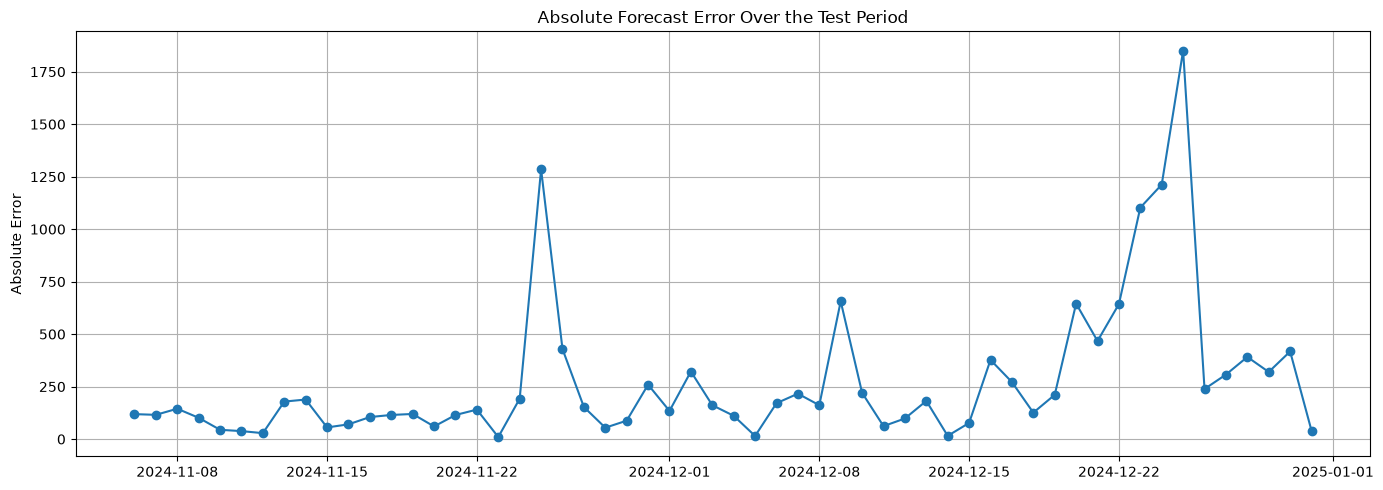

In [35]:
# Plot test errors
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(error_analysis.index, error_analysis["Absolute Error"], marker="o")

ax.set_title("Absolute Forecast Error Over the Test Period")
ax.set_ylabel("Absolute Error")
ax.grid(True)

plt.tight_layout()
plt.show()

**Final Evaluation and Error Analysis**
* The selected model is refitted using all development observations and evaluated on the previously reserved test period. Its MAE and RMSE are compared with the seasonal-naive baseline.
* MAE measures the average absolute error, while RMSE gives more weight to large errors. Weekday-level error analysis helps identify whether the forecasting system performs differently across the weekly cycle.
* The final results should be interpreted cautiously because they represent one held-out period. Unexpected promotions, holidays, missing records, or changes in customer behavior may lead to different future performance.
* The final model should be considered useful only if its results and error patterns justify using it instead of the simpler baseline.

### **Task 08 — Production considerations: freshness, serving, and monitoring**

**1. Data Freshness**
* Sales data should be refreshed daily after the previous day's sales have been finalized. Late transactions and missing records should be checked before generating forecasts. Features should be recalculated using only data available at prediction time.

**2. Batch vs Real-Time Serving**
* A daily batch forecasting system is suitable because the model predicts daily retail sales rather than individual real-time events. Forecasts can be generated after the daily data refresh and stored for reporting or inventory planning.

**3. Evaluation and Monitoring**
* Monitor MAE and RMSE when actual sales become available. Track missing data, feature distributions, forecast errors by weekday, and changes in demand. Compare the model against the seasonal-naive baseline regularly.

**4. Operational Risks and Fallback**
* If the model fails or required features are missing, use the seasonal-naive forecast as a fallback. Investigate persistent increases in forecast error, data pipeline failures, and significant distribution changes.

**5. Retraining**
* Review model performance regularly and retrain when sufficient new data is available or when monitoring indicates sustained deterioration. Validate the updated model on later historical periods before replacing the production model.